In [2]:
import numpy as np
import numpy.typing as npt
import scipy.stats

import matplotlib.pyplot as plt

In [1]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

In [70]:
# Target distribution
def p(x):
    return scipy.stats.gamma(a=3, scale=1/3).pdf(x)

# Proposal distribution
def q(x):
    return scipy.stats.norm(loc=0.5, scale=1.3).pdf(x) * 3


def samples(n: int, target, proposal, M: float, low: float, high: float, max_calls=int(1e8)) -> npt.NDArray[float]:
    n_samples = 0
    samples = np.zeros(n)
    calls = 0

    while n_samples < n:

        if calls >= max_calls:
            print('Max Calls Reached')
            break

        # generate sample
        x = np.random.uniform(low, high)
        p = target(x)
        q = proposal(x)

        u = np.random.uniform(0, 1)

        if u  < p/(M * q):
            samples[n_samples] += x
            n_samples += 1

        calls += 1

    return samples


In [71]:
rej_sampled = samples(int(1e4), p, q, M=1, low=-.5, high=6)


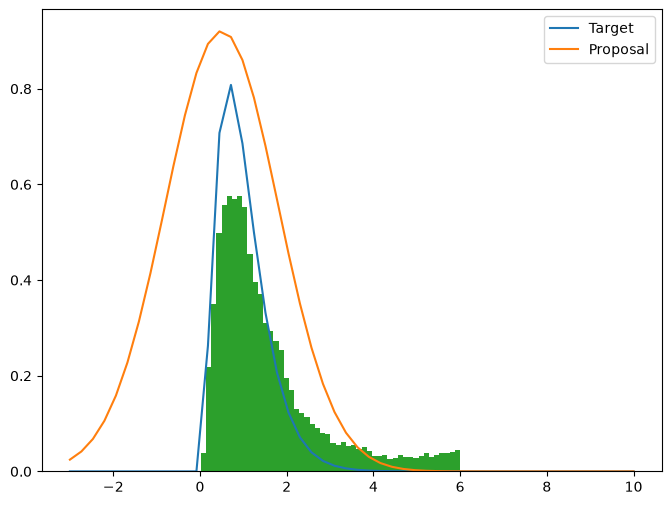

In [73]:
fig, ax = plt.subplots(figsize=(8,6))

xs = np.linspace(-3, 10)

ax.plot(xs, p(xs), label='Target')
ax.plot(xs, q(xs), label='Proposal')

# ax.set_xlim(-3, 4.5)

ax.hist(rej_sampled, 50, density=True)


ax.legend()



### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [2]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

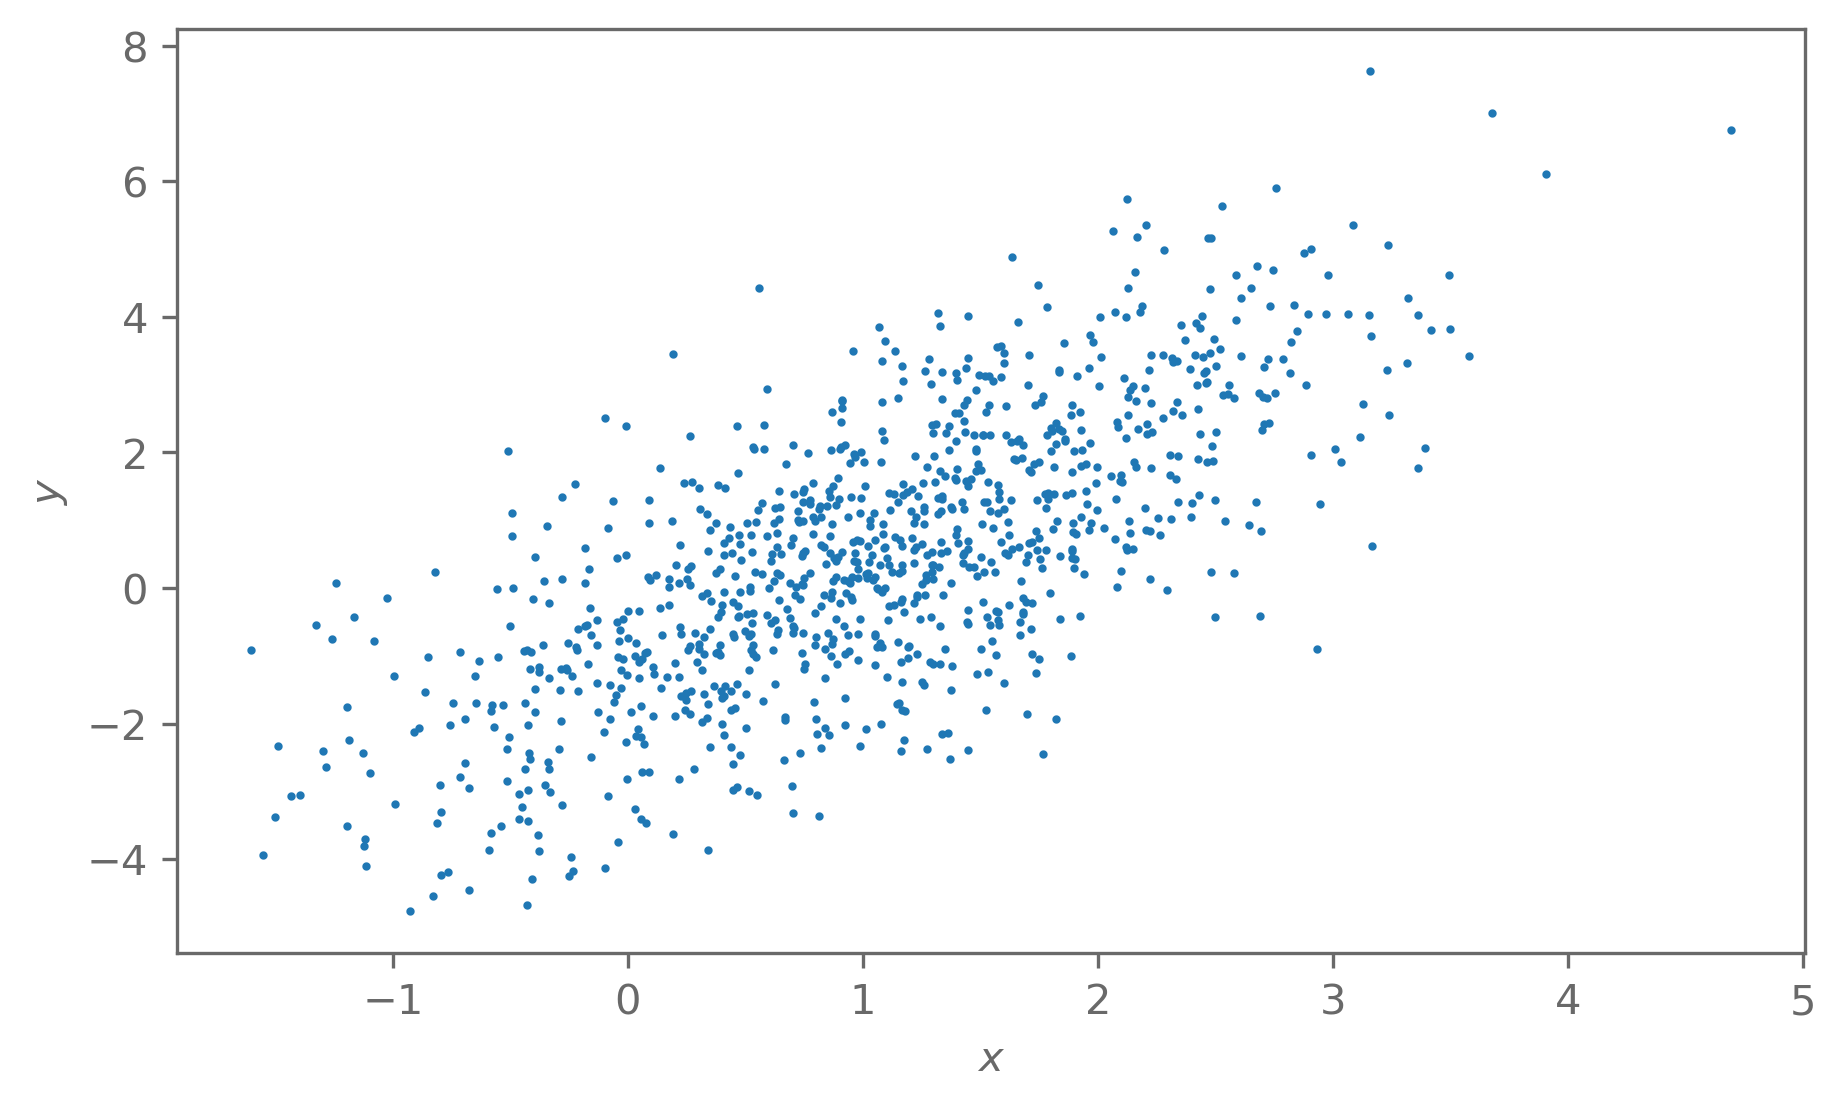

In [ ]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");